# Task 2 (Milestone 2) - Member 1: Data Foundation and Descriptive Statistics

**Dataset:** `combined_runs.csv`. **Random experiment used in this part:** pick one 5-minute time step at random from the steps of the 60 runs.



# 1. Setup
**Purpose.** Load the raw dataset once and keep it untouched in `df_raw`. The load cells below are copied unchanged from the Task 1 notebook (loader that tries the local file, GitHub, Drive, then an upload).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import os

SEED = 42                                  # fixed random seed used everywhere in the notebook
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# ---- Where the data comes from -------------------------------------------------
# The loader tries these sources in order and uses the first one that works:
#   1. a copy of the file in the current Colab folder (drag it into the Files panel)
#   2. the GitHub repo (compressed .gz, pandas reads it directly)
#   3. the shared Google Drive folder (only works if Drive is mounted)
#   4. an upload dialog as the last resort
REPO   = "https://raw.githubusercontent.com/Jana-Hazem/smart-buildings-statistics-project/main"
RAW  = REPO + "/data/raw/combined_runs.csv"
NAME = "combined_runs.csv"                 # the dataset file name
SOURCES = [NAME, NAME + ".gz", "/content/" + NAME,
           RAW,                                      # GitHub copy of the same file
           REPO + "/data/raw/" + NAME + ".gz",
           "/content/drive/MyDrive/stats_project/" + NAME]

def load_raw():
    for s in SOURCES:
        if s.startswith("http") or os.path.exists(s):
            try:
                d = pd.read_csv(s)
                print("Loaded from:", s)
                return d
            except Exception as e:
                print("Could not read", s, "->", type(e).__name__)
    from google.colab import files           # last resort: manual upload
    up = files.upload()
    return pd.read_csv(next(iter(up)))

In [2]:
# Small helper used by every text cell that contains numbers (so numbers are never typed by hand)
from IPython.display import display, Markdown
def say(text):
    display(Markdown(text))

In [3]:
# Load the raw data. df_raw is never modified after this line.
df_raw = load_raw()
print(df_raw.shape)          # expected: (241920, 37)

Loaded from: https://raw.githubusercontent.com/Jana-Hazem/smart-buildings-statistics-project/main/data/raw/combined_runs.csv
(241920, 37)


In [4]:
# Sanity check against the expected size
assert df_raw.shape == (241920, 37), f"Unexpected shape: {df_raw.shape}"
print("Shape confirmed: 241,920 rows x 37 columns")

Shape confirmed: 241,920 rows x 37 columns


# 2. Dataset recap and preprocessing log
No new analysis is done here. The quality-check cell, the cleaning cell and the run/building table cell are **copied unchanged from Task 1**. Only a short live recap is added after them.

## 2.1 Quality checks
Each check counts violations, so 0 means the property holds. These checks justify keeping every row.

In [5]:
checks = {}
g = df_raw.groupby("run_id")

# completeness
checks["missing values (total)"] = int(df_raw.isna().sum().sum())
checks["duplicated rows"] = int(df_raw.duplicated().sum())

# run structure
checks["runs without exactly 4032 steps"] = int((g.size() != 4032).sum())
checks["runs where step is not 0..4031"] = int(
    g.step.apply(lambda s: not (s.sort_values().to_numpy() == np.arange(4032)).all()).sum())
ts = pd.to_datetime(df_raw.timestamp)
gap = ts.groupby(df_raw.run_id).diff().dropna()
checks["time gaps not equal to 5 min"] = int((gap != pd.Timedelta(minutes=5)).sum())

# the two policies share the same conditions within a (building, weather) pair
shared = ["timestamp", "occupancy", "outside_air_temp_K"]
bad_pairs = 0
for _, p in df_raw.groupby(["building", "weather"]):
    a = p[p.policy == "pid_water"].sort_values("step")[shared].reset_index(drop=True)
    b = p[p.policy == "noisy_pid_water"].sort_values("step")[shared].reset_index(drop=True)
    if not a.equals(b):
        bad_pairs += 1
checks["pairs with different timestamp/occupancy/outside temp"] = bad_pairs

# redundancy and constants
checks["rows where reward != rc_agent_reward"] = int((df_raw.reward != df_raw.rc_agent_reward).sum())
checks["constant cols (done, run_status, run_steps) not constant"] = int(
    sum(df_raw[c].nunique() != 1 for c in ["done", "run_status", "run_steps"]))
checks["rows where run_id != building__weather__policy"] = int(
    (df_raw.run_id != df_raw.building + "__" + df_raw.weather + "__" + df_raw.policy).sum())

# run-level and building-level columns
run_cols = [c for c in df_raw.columns if c.startswith("run_") and c != "run_id"]
checks["run_* columns with >1 value in a run"] = int(sum((g[c].nunique() > 1).any() for c in run_cols))
for c in ["run_n_zones", "run_n_floors", "run_n_ahus"]:
    checks[f"buildings with >1 value of {c}"] = int((df_raw.groupby("building")[c].nunique() > 1).sum())

qc = pd.Series(checks, name="violations")
print(qc.to_string())
print("Distinct buildings:", df_raw.building.nunique())

missing values (total)                                      0
duplicated rows                                             0
runs without exactly 4032 steps                             0
runs where step is not 0..4031                              0
time gaps not equal to 5 min                                0
pairs with different timestamp/occupancy/outside temp       0
rows where reward != rc_agent_reward                        0
constant cols (done, run_status, run_steps) not constant    0
rows where run_id != building__weather__policy              0
run_* columns with >1 value in a run                        0
buildings with >1 value of run_n_zones                      0
buildings with >1 value of run_n_floors                     0
buildings with >1 value of run_n_ahus                       0
Distinct buildings: 6


## 2.2 Cleaning and derived columns
`df_raw` stays untouched. All work happens on the copy `df`, and every step is logged with its row and column count.

In [6]:
log = []
def step(name, d):
    log.append((name, len(d), d.shape[1]))
    print(f"{name}: {len(d)} rows x {d.shape[1]} cols")

step("raw", df_raw)
df = df_raw.copy()                                   # all work happens on the copy

# 1. missing values / duplicates: none, so nothing is removed
assert df.isna().sum().sum() == 0 and df.duplicated().sum() == 0
step("remove missing/duplicates (none found)", df)

# 2. drop constant and redundant columns (analysis frame only)
const = [c for c in df.columns if df[c].nunique() == 1]       # done, run_status, run_steps
red = ["rc_agent_reward", "run_score_abs_mean", "run_total_reward"]
assert (df.reward == df.rc_agent_reward).all()
df = df.drop(columns=const + red)
step(f"drop constants {const} + redundant {red}", df)

# 3. parse and derive (run_id already exists, so it is not rebuilt)
df["ts"]      = pd.to_datetime(df.timestamp)
df["city"]    = df.weather.str.rsplit("_", n=1).str[0]
df["pair_id"] = df.building + "|" + df.weather
df["hour"], df["dow"] = df.ts.dt.hour, df.ts.dt.dayofweek    # dow: 0 = Monday
df["day"]     = df.step // 288                               # 288 five-minute steps per day
step("add derived columns", df)

assert df.groupby("run_id").size().eq(4032).all() and df.run_id.nunique() == 60
pd.DataFrame(log, columns=["step", "rows", "columns"])

raw: 241920 rows x 37 cols
remove missing/duplicates (none found): 241920 rows x 37 cols
drop constants ['done', 'run_status', 'run_steps'] + redundant ['rc_agent_reward', 'run_score_abs_mean', 'run_total_reward']: 241920 rows x 31 cols
add derived columns: 241920 rows x 37 cols


,step,rows,columns
0,raw,241920,37
1,remove missing/duplicates (none found),241920,37
2,"drop constants ['done', 'run_status', 'run_ste...",241920,31
3,add derived columns,241920,37


## 2.3 Run table and building table
The `run_*` columns repeat on every row of a run, so run-level statistics must use the one-row-per-run table `runs`, never all rows.

In [25]:
runs = df.drop_duplicates("run_id").set_index("run_id")
bld  = df.drop_duplicates("building").set_index("building")[
        ["run_n_zones", "run_n_floors", "run_n_ahus",
         "run_n_obs", "run_n_cont_actions", "run_n_disc_actions"]]

assert runs.shape[0] == 60 and bld.shape[0] == 6
print("runs:", runs.shape, "| bld:", bld.shape)
bld

runs: (60, 43) | bld: (6, 6)


,run_n_zones,run_n_floors,run_n_ahus,run_n_obs,run_n_cont_actions,run_n_disc_actions
building,,,,,,
building_train_1,39,3,4,352,92,5
building_train_2,85,2,9,703,199,10
building_train_4,54,3,6,472,128,7
building_train_5,79,4,8,652,184,9
building_train_7,36,2,4,334,86,5
building_train_8,30,2,3,283,71,4


## 2.4 Recap (live)

In [26]:
steps_per_run = int(df_raw.groupby("run_id").size().iloc[0])
say(f'''
**What the data is.** `combined_runs.csv` has **{df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns**. **One row = one 5-minute step** of one simulated building run.
A run is one building under one weather file and one controller. There are **{df_raw.run_id.nunique()} runs** = {df_raw.building.nunique()} buildings x {df_raw.weather.nunique()} cities x {df_raw.policy.nunique()} policies, each with **{steps_per_run:,} steps** ({df.day.nunique()} days).

**Quality.** The {len(qc)} quality checks give **{int(qc.sum())} violations** in total: no missing values, no duplicates, the same step structure in every run.

**Row log.** Rows kept: **{len(df):,}** of {len(df_raw):,} (nothing removed). Columns: {df_raw.shape[1]} raw -> {df.shape[1]} after dropping {len(const) + len(red)} constant or redundant columns and adding {df.shape[1] - (df_raw.shape[1] - len(const) - len(red))} derived columns.

**Honest sample sizes.** The {len(df):,} rows are *time steps*, not independent samples: steps in a run are linked in time. The real units are {runs.shape[0]} runs and {bld.shape[0]} buildings.
''')


**What the data is.** `combined_runs.csv` has **241,920 rows x 37 columns**. **One row = one 5-minute step** of one simulated building run.
A run is one building under one weather file and one controller. There are **60 runs** = 6 buildings x 30 cities x 2 policies, each with **4,032 steps** (14 days).

**Quality.** The 13 quality checks give **0 violations** in total: no missing values, no duplicates, the same step structure in every run.

**Row log.** Rows kept: **241,920** of 241,920 (nothing removed). Columns: 37 raw -> 44 after dropping 6 constant or redundant columns and adding 13 derived columns.

**Honest sample sizes.** The 241,920 rows are *time steps*, not independent samples: steps in a run are linked in time. The real units are 60 runs and 6 buildings.


# 3. New columns, new tables and shared names
This is the only new work in the data foundation: seven extra columns, three new tables and the shared names for Members 2 to 5.

**Sorting.** Streaks are only valid if the steps of each run are in time order, so `df` is first sorted by `run_id` and `step` and the index is reset.

**Event columns (same definitions as Task 1, Section 4).** Each is a True/False column; strict inequalities are used throughout.
- `OCC` occupied: `occupancy > 0`
- `HP` heavy penalty: `reward < -0.1`
- `NOISY` noisy controller: `policy == "noisy_pid_water"`
- `COLD` outside air below 10 C (283.15 K) and `HOT` above 25 C (298.15 K) - temperatures stay in Kelvin
- `WD` weekday: `dow < 5`

**Hour-block id.** `hblock = step // 12` numbers the 12-step blocks (one clock hour) inside a run. It links `df` to the hour-block table.

In [9]:
# sort first (needed for streaks), then add the seven new columns
df = df.sort_values(["run_id", "step"]).reset_index(drop=True)

df["OCC"]    = df.occupancy > 0                       # occupied step
df["HP"]     = df.reward < -0.1                       # heavy-penalty step
df["NOISY"]  = df.policy == "noisy_pid_water"         # noisy controller
df["COLD"]   = df.outside_air_temp_K < 283.15         # below 10 C
df["HOT"]    = df.outside_air_temp_K > 298.15         # above 25 C
df["WD"]     = df.dow < 5                             # weekday (Monday = 0)
df["hblock"] = df.step // 12                          # hour-block number inside the run (0 to 335)

events = ["OCC", "HP", "NOISY", "COLD", "HOT", "WD"]
p_hp  = df.HP.mean()                                  # P(HP), shared with M2, M3, M4
p_occ = df.OCC.mean()

# refresh the run table now that the event columns exist (60 rows, one per run)
runs = df.drop_duplicates("run_id").set_index("run_id")
assert runs.shape[0] == 60

step("sort + 7 new columns (OCC, HP, NOISY, COLD, HOT, WD, hblock)", df)
print(f"P(OCC) = {p_occ:.4f}   P(HP) = {p_hp:.4f}   HP steps = {int(df.HP.sum()):,}")

sort + 7 new columns (OCC, HP, NOISY, COLD, HOT, WD, hblock): 241920 rows x 44 cols
P(OCC) = 0.3735   P(HP) = 0.2007   HP steps = 48,550


## 3.1 Penalty streaks table `spells`
**Definition.** A *penalty streak* is a maximal run of consecutive `HP` steps inside one run. A streak starts at an HP step whose previous step in the same run is not HP (the first step of a run has no previous step, so an HP first step also starts a streak). Streaks never cross from one run to the next. Each streak is assigned to the day and hour of its first step.

In [27]:
is_hp   = df.HP.to_numpy()
new_run = df.run_id.ne(df.run_id.shift(1)).to_numpy()          # True on the first row of every run
prev_hp = np.r_[False, is_hp[:-1]]
prev_hp[new_run] = False                                        # no previous step at the start of a run
onset   = is_hp & ~prev_hp                                      # True where a streak starts
spell_no = np.cumsum(onset)                                     # streak number carried along the rows

hp_rows = df.loc[is_hp, ["run_id", "building", "city", "policy", "step", "day", "hour"]].copy()
hp_rows["spell"] = spell_no[is_hp]
spells = (hp_rows.groupby("spell")
          .agg(run_id=("run_id", "first"), building=("building", "first"), city=("city", "first"),
               policy=("policy", "first"), start_step=("step", "min"), end_step=("step", "max"),
               length=("step", "size"), day=("day", "first"), hour=("hour", "first"))
          .reset_index(drop=True))

# the steps of a streak must be consecutive
assert (spells.length == spells.end_step - spells.start_step + 1).all()
print("spells:", spells.shape, "| streak length: min", spells.length.min(), "max", spells.length.max())
spells.head()

spells: (7018, 9) | streak length: min 1 max 379


,run_id,building,city,policy,start_step,end_step,length,day,hour
0,building_train_1__atlanta_2__noisy_pid_water,building_train_1,atlanta,noisy_pid_water,729,729,1,2,18
1,building_train_1__atlanta_2__noisy_pid_water,building_train_1,atlanta,noisy_pid_water,863,863,1,2,6
2,building_train_1__atlanta_2__noisy_pid_water,building_train_1,atlanta,noisy_pid_water,1241,1241,1,4,13
3,building_train_1__atlanta_2__noisy_pid_water,building_train_1,atlanta,noisy_pid_water,1246,1246,1,4,13
4,building_train_1__atlanta_2__noisy_pid_water,building_train_1,atlanta,noisy_pid_water,1249,1250,2,4,14


## 3.2 Hour-block table `hb`
One row per hour-block of 12 steps. `X` = number of HP steps in the block (0 to 12).

In [28]:
hb = (df.groupby(["run_id", "hblock"])
      .agg(building=("building", "first"), city=("city", "first"), policy=("policy", "first"),
           day=("day", "first"), hour=("hour", "first"), WD=("WD", "first"),
           X=("HP", "sum"), occ_steps=("OCC", "sum"), n_steps=("step", "size"))
      .reset_index())

assert (hb.n_steps == 12).all() and hb.X.between(0, 12).all()
print("hb:", hb.shape, "| X from", hb.X.min(), "to", hb.X.max())
print("block hour equals clock hour of its first step in every block:", bool((hb.hour == hb.hblock % 24).all()))
hb.head()

hb: (20160, 11) | X from 0 to 12
block hour equals clock hour of its first step in every block: False


,run_id,hblock,building,city,policy,day,hour,WD,X,occ_steps,n_steps
0,building_train_1__atlanta_2__noisy_pid_water,0,building_train_1,atlanta,noisy_pid_water,0,6,False,0,0,12
1,building_train_1__atlanta_2__noisy_pid_water,1,building_train_1,atlanta,noisy_pid_water,0,7,False,0,0,12
2,building_train_1__atlanta_2__noisy_pid_water,2,building_train_1,atlanta,noisy_pid_water,0,8,False,0,0,12
3,building_train_1__atlanta_2__noisy_pid_water,3,building_train_1,atlanta,noisy_pid_water,0,9,False,0,0,12
4,building_train_1__atlanta_2__noisy_pid_water,4,building_train_1,atlanta,noisy_pid_water,0,10,False,0,0,12


## 3.3 Run-day table `rd`
One row per run and day (a run lasts several days). `n_onsets` = number of penalty streaks that *start* on that day; `n_hp_steps` = HP steps on that day.

In [29]:
rd = (df.groupby(["run_id", "day"])
      .agg(building=("building", "first"), city=("city", "first"), policy=("policy", "first"),
           WD=("WD", "first"), n_hp_steps=("HP", "sum"), n_occ_steps=("OCC", "sum"))
      .reset_index())
onsets = spells.groupby(["run_id", "day"]).size().rename("n_onsets")
rd = rd.merge(onsets, on=["run_id", "day"], how="left")
rd["n_onsets"] = rd.n_onsets.fillna(0).astype(int)

print("rd:", rd.shape)
rd.head()

rd: (840, 9)


,run_id,day,building,city,policy,WD,n_hp_steps,n_occ_steps,n_onsets
0,building_train_1__atlanta_2__noisy_pid_water,0,building_train_1,atlanta,noisy_pid_water,False,0,1,0
1,building_train_1__atlanta_2__noisy_pid_water,1,building_train_1,atlanta,noisy_pid_water,True,0,156,0
2,building_train_1__atlanta_2__noisy_pid_water,2,building_train_1,atlanta,noisy_pid_water,True,2,156,2
3,building_train_1__atlanta_2__noisy_pid_water,3,building_train_1,atlanta,noisy_pid_water,True,0,156,0
4,building_train_1__atlanta_2__noisy_pid_water,4,building_train_1,atlanta,noisy_pid_water,True,16,156,10


## 3.4 Check: the number of HP steps must be the same in every table
Three routes (as required by the guide): `df`, `hb` and `spells`. `rd` is added as a fourth check. If any route disagrees, the tables are wrong and nobody should use them.

In [30]:
hp_df, hp_hb, hp_sp, hp_rd = int(df.HP.sum()), int(hb.X.sum()), int(spells.length.sum()), int(rd.n_hp_steps.sum())
print(f"HP steps from df     : {hp_df:,}")
print(f"HP steps from hb     : {hp_hb:,}")
print(f"HP steps from spells : {hp_sp:,}")
print(f"HP steps from rd     : {hp_rd:,}")
assert hp_df == hp_hb == hp_sp == hp_rd, "HP step counts disagree between tables"
assert int(rd.n_onsets.sum()) == len(spells), "streak starts in rd differ from rows of spells"
say(f"**Check passed (exact).** All tables hold the same **{hp_df:,}** heavy-penalty steps, and the {len(spells):,} streak starts in `rd` equal the rows of `spells`.")

HP steps from df     : 48,550
HP steps from hb     : 48,550
HP steps from spells : 48,550
HP steps from rd     : 48,550


**Check passed (exact).** All tables hold the same **48,550** heavy-penalty steps, and the 7,018 streak starts in `rd` equal the rows of `spells`.

## 3.5 Helper and shared names (posted to the team)
**Helper `summ`.** Returns the descriptive tools: n, mean and standard deviation (divisor n - 1).

The names below are shared with the other members; nobody renames them.

In [31]:
def summ(x):
    # n, mean and standard deviation (divisor n - 1) of a numeric column
    x = pd.Series(x).astype(float)
    return pd.Series({"n": x.size, "mean": x.mean(), "sd": x.std(ddof=1)})

shared = pd.DataFrame([
    ("df",                   "analysis table, one row per time step",              f"{df.shape[0]:,} x {df.shape[1]}"),
    ("runs",                 "analysis table, one row per run",                    f"{runs.shape[0]} rows"),
    ("OCC, HP, WD, NOISY",   "occupied, heavy penalty, weekday, noisy policy",     "True/False columns of df"),
    ("COLD, HOT, hblock",    "cold, hot, hour-block number",                       "columns of df"),
    ("hb",                   "hour-block table (X = HP steps in the block)",       f"{len(hb):,} rows"),
    ("rd",                   "run-day table (streak starts per day)",              f"{len(rd):,} rows"),
    ("spells",               "penalty-streak table",                               f"{len(spells):,} rows"),
    ("p_hp",                 "P(HP)",                                              f"{p_hp:.4f}"),
    ("summ",                 "helper: n, mean, sd",                                "function"),
], columns=["name", "what", "size"])
shared

,name,what,size
0,df,"analysis table, one row per time step","241,920 x 44"
1,runs,"analysis table, one row per run",60 rows
2,"OCC, HP, WD, NOISY","occupied, heavy penalty, weekday, noisy policy",True/False columns of df
3,"COLD, HOT, hblock","cold, hot, hour-block number",columns of df
4,hb,hour-block table (X = HP steps in the block),"20,160 rows"
5,rd,run-day table (streak starts per day),840 rows
6,spells,penalty-streak table,"7,018 rows"
7,p_hp,P(HP),0.2007
8,summ,"helper: n, mean, sd",function


# 4. Chapter 6 - Descriptive Statistics

| Tool | Formula or rule |
|---|---|
| Mean | $\bar x = \frac{1}{n}\sum x_i$ |
| Variance and standard deviation | $s^2 = \frac{\sum (x_i-\bar x)^2}{n-1}$, $s=\sqrt{s^2}$ |
| Scatter graph | The two variables are drawn as points in a 2-D plane |
| Covariance | $\sigma_{XY}=E[(X-\mu_X)(Y-\mu_Y)]=E(XY)-\mu_X\mu_Y$; by hand: $\frac{\sum (x_i-\bar x)(y_i-\bar y)}{n-1}$ |
| Correlation coefficient r | $r=\frac{\mathrm{cov}(x,y)}{\sqrt{\mathrm{var}(x)\mathrm{var}(y)}}$, always between -1 and +1 |
| Strength scale for r | Strong: 0.7 to 1; moderate: 0.3 to 0.7; weak: 0.1 to 0.3; none: below 0.1 (same scale for negative r) |
| r sees only straight lines | Linear versus curvilinear relationships |



## 4.1 Application 1: Summaries by group


**Question.** How do reward and occupancy differ between the two controller policies, between occupied and empty steps, and between the five cities?

**Variables and assumptions.**
- Experiment: pick one 5-minute time step at random from all the steps.
- `reward` (continuous, never positive, higher is better) and `occupancy` (number of people, discrete).
- Groups: `policy`, occupancy status (`OCC` from Section 3: occupied / empty) and `city`.
- The steps of a run are linked in time, so the numbers describe these 60 runs.



In [32]:
def mean_sd_manual(x):
    x = np.asarray(x, dtype=float)
    n = x.size
    m = x.sum() / n
    var = ((x - m) ** 2).sum() / (n - 1)
    return m, np.sqrt(var)

def group_table(by, with_occ=True):
    cols = dict(n_steps=("reward", "size"), reward_mean=("reward", "mean"), reward_sd=("reward", "std"))
    if with_occ:
        cols.update(occ_mean=("occupancy", "mean"), occ_sd=("occupancy", "std"))
    return df.groupby(by).agg(**cols)

status = df.OCC.map({True: "occupied", False: "empty"}).rename("occupancy status")

tab_all    = pd.DataFrame({"n_steps": [len(df)], "reward_mean": [df.reward.mean()], "reward_sd": [df.reward.std()],
                           "occ_mean": [df.occupancy.mean()], "occ_sd": [df.occupancy.std()]}, index=["all steps"])
tab_policy = group_table(df.policy)
tab_occ    = group_table(status, with_occ=False)
tab_city   = group_table(df.city)

for title, t in [("All steps", tab_all), ("By policy", tab_policy), ("By occupancy status", tab_occ), ("By city", tab_city)]:
    print(f"\n{title}")
    display(t.round(4))


All steps


,n_steps,reward_mean,reward_sd,occ_mean,occ_sd
all steps,241920,-0.0623,0.1198,17.851,33.0888



By policy


,n_steps,reward_mean,reward_sd,occ_mean,occ_sd
policy,,,,,
noisy_pid_water,120960,-0.0665,0.1177,17.851,33.0889
pid_water,120960,-0.0581,0.1218,17.851,33.0889



By occupancy status


,n_steps,reward_mean,reward_sd
occupancy status,,,
empty,151568,-0.0088,0.0314
occupied,90352,-0.1521,0.1547



By city


,n_steps,reward_mean,reward_sd,occ_mean,occ_sd
city,,,,,
atlanta,48384,-0.0398,0.0705,18.4743,33.7484
denver,48384,-0.0400,0.0671,17.8820,33.0517
fairbanks,48384,-0.0944,0.1795,17.1766,32.3895
phoenix,48384,-0.0800,0.1331,17.7860,33.0272
singapore,48384,-0.0573,0.1001,17.9359,33.2014


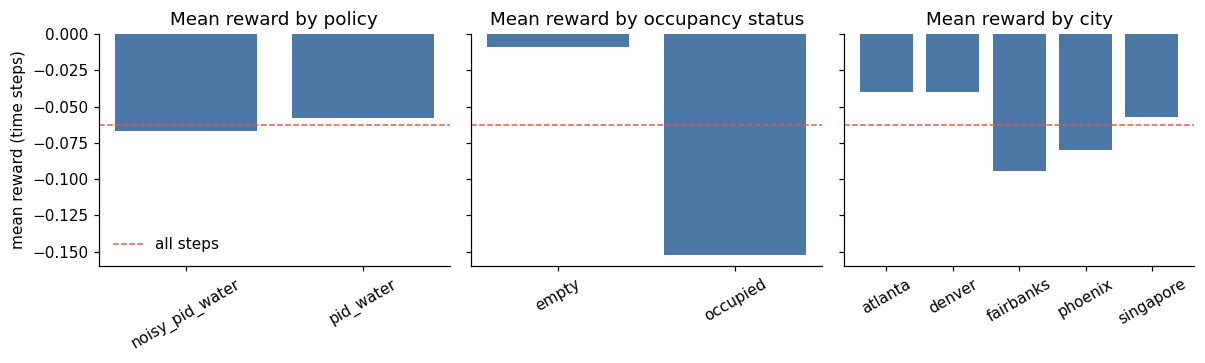

In [16]:
# Chart: mean reward in each group (the standard deviations are in the tables above)
fig, ax = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for a, t, name in [(ax[0], tab_policy, "policy"), (ax[1], tab_occ, "occupancy status"), (ax[2], tab_city, "city")]:
    a.bar(t.index.astype(str), t.reward_mean, color="#4C78A8")
    a.axhline(df.reward.mean(), color="#E45756", lw=1, ls="--", label="all steps")
    a.set_title(f"Mean reward by {name}")
    a.tick_params(axis="x", rotation=30)
ax[0].set_ylabel("mean reward (time steps)")
ax[0].legend(frameon=False)
plt.tight_layout(); plt.show()

**Validation (exact).** Every key number is computed three ways: (1) the formula by hand, (2) pandas, (3) an independent loop over the 60 runs (or over the groups) that does not use `groupby().mean()`. The three must agree to rounding.

In [17]:
res_M1 = {}   # name -> (formula, direct, independent, kind), the format M5 expects

def record(name, formula, direct, independent, kind="exact"):
    res_M1[name] = (float(formula), float(direct), float(independent), kind)
    if kind == "exact":
        assert np.isclose(formula, direct) and np.isclose(formula, independent), f"{name}: the three routes disagree"

# overall mean and sd
m_f, s_f = mean_sd_manual(df.reward)                              # route 1: formula
m_d, s_d = df.reward.mean(), df.reward.std()                      # route 2: pandas
tot = n_tot = 0                                                    # route 3: loop over the 60 runs
for _, g in df.groupby("run_id"):
    tot += g.reward.sum(); n_tot += len(g)
m_i, s_i = tot / n_tot, np.std(df.reward.to_numpy(), ddof=1)       # sd: numpy with divisor n - 1
record("reward mean, all steps", m_f, m_d, m_i)
record("reward sd, all steps",   s_f, s_d, s_i)

# occupied and empty steps
for label, mask in [("occupied", df.OCC), ("empty", ~df.OCC)]:
    f = mean_sd_manual(df.reward[mask])[0]
    d = tab_occ.loc[label, "reward_mean"]
    s = sum(g.reward[g.OCC == (label == "occupied")].sum() for _, g in df.groupby("run_id")) / int(mask.sum())
    record(f"reward mean, {label} steps", f, d, s)

# every group mean and sd in the policy, occupancy and city tables: manual formula vs the table
gaps = []
for t, key in [(tab_policy, df.policy), (tab_occ, status), (tab_city, df.city)]:
    for grp in t.index:
        m, s = mean_sd_manual(df.reward[(key == grp).to_numpy()])
        gaps += [abs(m - t.loc[grp, "reward_mean"]), abs(s - t.loc[grp, "reward_sd"])]
record("largest gap over all group means and sds", max(gaps), 0.0, 0.0)

val_41 = pd.DataFrame(res_M1, index=["formula", "direct", "independent", "kind"]).T
val_41

,formula,direct,independent,kind
"reward mean, all steps",-0.062305,-0.062305,-0.062305,exact
"reward sd, all steps",0.119839,0.119839,0.119839,exact
"reward mean, occupied steps",-0.15206,-0.15206,-0.15206,exact
"reward mean, empty steps",-0.0088,-0.0088,-0.0088,exact
largest gap over all group means and sds,0.0,0.0,0.0,exact


In [33]:
occ_m, emp_m = tab_occ.loc["occupied", "reward_mean"], tab_occ.loc["empty", "reward_mean"]
pol = tab_policy.reward_mean
best_city, worst_city = tab_city.reward_mean.idxmax(), tab_city.reward_mean.idxmin()
say(f'''
**Interpretation.**
- Over all {len(df):,} time steps the mean reward is **{tab_all.reward_mean.iloc[0]:.4f}** with a standard deviation of **{tab_all.reward_sd.iloc[0]:.4f}**. {"The spread is larger than the size of the mean, so single steps vary a lot around the average level." if tab_all.reward_sd.iloc[0] > abs(tab_all.reward_mean.iloc[0]) else "The spread is smaller than the size of the mean."}
- Occupancy matters: occupied steps average **{occ_m:.4f}** and empty steps **{emp_m:.4f}**. {"The average occupied step is about **" + f"{abs(occ_m / emp_m):.1f}" + " times as negative** as an empty one: reward is lower when people are in the building." if occ_m < emp_m else "Occupied steps have the higher mean reward."}
- Policies: `pid_water` averages {pol["pid_water"]:.4f} and `noisy_pid_water` {pol["noisy_pid_water"]:.4f}.
- Cities: the highest mean reward is in **{best_city}** ({tab_city.reward_mean.max():.4f}) and the lowest in **{worst_city}** ({tab_city.reward_mean.min():.4f}).
- These are descriptions of the {runs.shape[0]} runs in this file. No claim is made that a difference is statistically real. The validation table shows that formula, pandas and loop agree (exact).
''')


**Interpretation.**
- Over all 241,920 time steps the mean reward is **-0.0623** with a standard deviation of **0.1198**. The spread is larger than the size of the mean, so single steps vary a lot around the average level.
- Occupancy matters: occupied steps average **-0.1521** and empty steps **-0.0088**. The average occupied step is about **17.3 times as negative** as an empty one: reward is lower when people are in the building.
- Policies: `pid_water` averages -0.0581 and `noisy_pid_water` -0.0665.
- Cities: the highest mean reward is in **atlanta** (-0.0398) and the lowest in **fairbanks** (-0.0944).
- These are descriptions of the 60 runs in this file. No claim is made that a difference is statistically real. The validation table shows that formula, pandas and loop agree (exact).


## 4.2 Application 2: Scatter graph and correlation

**Question.** Which measured conditions move together with reward, in which direction and how strongly?

**Variables and assumptions.**
- Experiment: pick one 5-minute time step at random; each time step gives a pair (X, reward).
- Y = `reward`. Candidates X: `occupancy`, `outside_air_temp_K`, `zone_temp_mean_K`, `zone_temp_min_K`, `zone_temp_max_K` (temperatures in Kelvin).
- The `rc_*` columns are **not** used as X: they are the pieces reward is built from, so their correlation with reward would say nothing about what drives it.
- The steps of a run are linked in time, so r describes these 60 runs pooled together; it is not an estimate from independent samples.

**Rule and why it fits.** The scatter graph shows each pair as a point. Pearson's r is the covariance divided by the two standard deviations, so it is unitless and always between -1 and +1. The sign gives the direction; the size gives how close the points lie to a straight line. Because r only sees straight-line relationships, a curved pattern could hide behind a small r, which is why the scatter plot is always drawn next to the number.

In [34]:
pairs = ["occupancy", "outside_air_temp_K", "zone_temp_mean_K", "zone_temp_min_K", "zone_temp_max_K"]
y = df.reward.to_numpy(float)

def cov_manual(x, y):
    # by hand: sum((x - mean_x)(y - mean_y)) / (n - 1)
    n = len(x)
    return ((x - x.sum() / n) * (y - y.sum() / n)).sum() / (n - 1)

def r_manual(x, y):
    # r = cov(x, y) / sqrt(var x * var y), all with divisor n - 1
    return cov_manual(x, y) / np.sqrt(cov_manual(x, x) * cov_manual(y, y))

def strength(r):
    # strength scale
    a = abs(r)
    word = "strong" if a >= 0.7 else "moderate" if a >= 0.3 else "weak" if a >= 0.1 else "no linear relationship"
    if word == "no linear relationship":
        return word
    return f"{word} {'positive' if r > 0 else 'negative'}"

rows = []
for c in pairs:
    x = df[c].to_numpy(float)
    rows.append(dict(variable=c, cov=cov_manual(x, y), r=r_manual(x, y),
                     r_numpy=np.corrcoef(x, y)[0, 1], r_pandas=df[c].corr(df.reward)))
corr_reward = pd.DataFrame(rows).set_index("variable")
corr_reward["strength"] = corr_reward.r.map(strength)
corr_reward.round(4)

,cov,r,r_numpy,r_pandas,strength
variable,,,,,
occupancy,-1.5622,-0.3940,-0.3940,-0.3940,moderate negative
outside_air_temp_K,0.2231,0.1235,0.1235,0.1235,weak positive
zone_temp_mean_K,0.0347,0.1196,0.1196,0.1196,weak positive
zone_temp_min_K,0.1100,0.2013,0.2013,0.2013,weak positive
zone_temp_max_K,-0.0332,-0.1471,-0.1471,-0.1471,weak negative


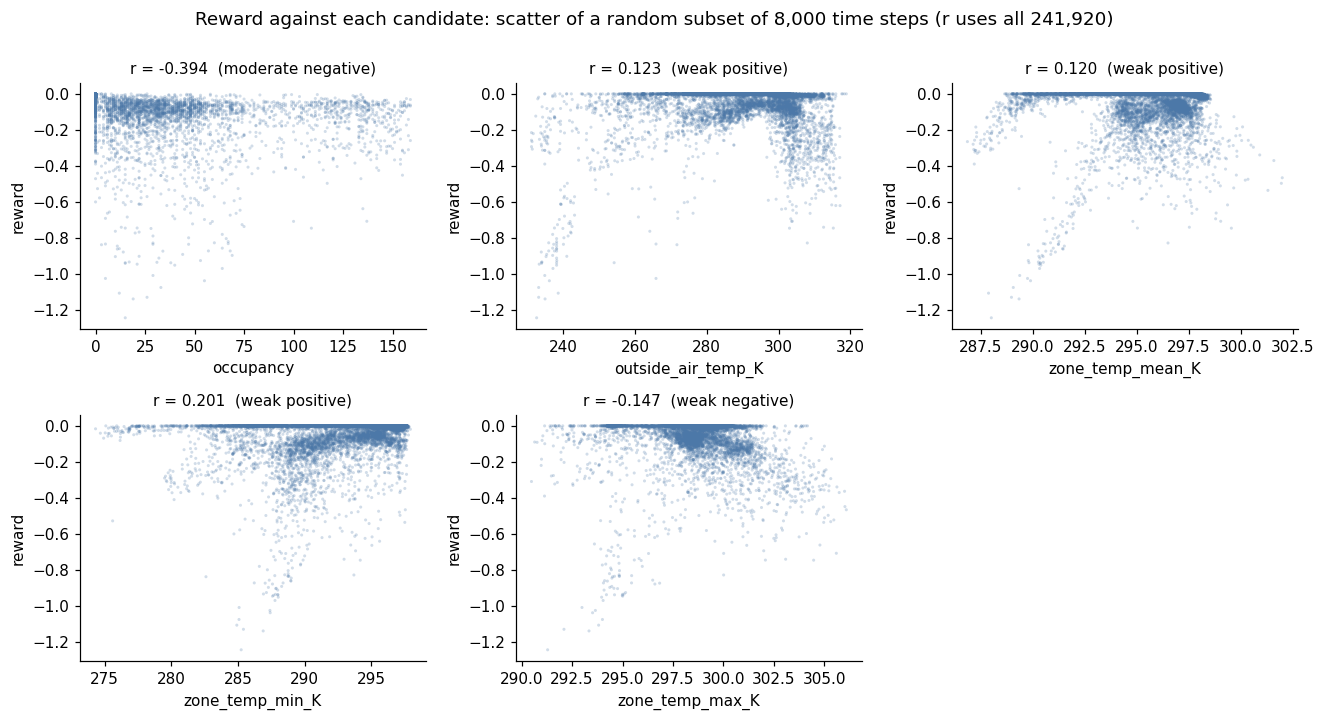

In [20]:
# Scatter graphs of reward against each candidate
# Drawing all time steps would hide the pattern, so the PLOT uses a random subset (seed 42); r is computed on ALL steps.
n_plot = 8000
idx = rng.choice(len(df), n_plot, replace=False)
sub = df.iloc[idx]

fig, ax = plt.subplots(2, 3, figsize=(12, 6.5))
for a, c in zip(ax.ravel(), pairs):
    a.scatter(sub[c], sub.reward, s=4, alpha=0.25, color="#4C78A8", edgecolors="none")
    a.set_xlabel(c); a.set_ylabel("reward")
    a.set_title(f"r = {corr_reward.loc[c, 'r']:.3f}  ({corr_reward.loc[c, 'strength']})", fontsize=10)
ax.ravel()[-1].axis("off")
fig.suptitle(f"Reward against each candidate: scatter of a random subset of {n_plot:,} time steps (r uses all {len(df):,})", y=1.0)
plt.tight_layout(); plt.show()

**Validation (exact).** For reward against occupancy: r and the covariance are computed by (1) hand, (2) numpy, (3) pandas. Covariance is also checked with the identity $E(XY)-\mu_X\mu_Y$; that form divides by n, so it is compared with the by-hand covariance rescaled to divisor n (the divisors must match for the comparison to be fair).

In [21]:
x = df.occupancy.to_numpy(float)
n = len(x)

# correlation: formula / numpy / pandas
record("r(reward, occupancy)", r_manual(x, y), np.corrcoef(x, y)[0, 1], df.occupancy.corr(df.reward))

# covariance, divisor n - 1: by hand / numpy / pandas
record("cov(reward, occupancy), divisor n-1", cov_manual(x, y), np.cov(x, y)[0, 1], df.occupancy.cov(df.reward))

# covariance, divisor n: E(XY) - mu_X mu_Y / by hand rescaled / numpy with bias=True
record("cov(reward, occupancy), divisor n",
       (x * y).mean() - x.mean() * y.mean(),
       cov_manual(x, y) * (n - 1) / n,
       np.cov(x, y, bias=True)[0, 1])

# r from covariance and the standard deviations of 4.1
record("r = cov / (sd_x * sd_y)", r_manual(x, y), df.occupancy.cov(df.reward) / (df.occupancy.std() * df.reward.std()), np.corrcoef(x, y)[0, 1])

print(pd.DataFrame({k: v for k, v in res_M1.items() if k.startswith(("r(", "cov", "r ="))},
                   index=["formula", "direct", "independent", "kind"]).T.to_string())

                                      formula    direct independent   kind
r(reward, occupancy)                -0.393957 -0.393957   -0.393957  exact
cov(reward, occupancy), divisor n-1 -1.562172 -1.562172   -1.562172  exact
cov(reward, occupancy), divisor n   -1.562166 -1.562166   -1.562166  exact
r = cov / (sd_x * sd_y)             -0.393957 -0.393957   -0.393957  exact


In [35]:
r_occ = corr_reward.loc["occupancy", "r"]
top = corr_reward.r.abs().idxmax()
zero_share = (df.occupancy == 0).mean()
say(f'''
**Interpretation.**
- Reward and occupancy: **r = {r_occ:.3f}**, a **{corr_reward.loc["occupancy", "strength"]}** relationship on the scale. {"More people in the building goes together with a lower (more negative) reward, which agrees with the group means of Section 4.1." if r_occ < 0 else "More people in the building goes together with a higher reward."}
- The strongest straight-line link among the five candidates is **{top}** (r = {corr_reward.loc[top, "r"]:.3f}); the weakest is **{corr_reward.r.abs().idxmin()}** (r = {corr_reward.loc[corr_reward.r.abs().idxmin(), "r"]:.3f}).
- In the occupancy scatter, {zero_share:.1%} of the time steps sit at occupancy 0, which forms a column of points on the left; the correlation is the combined effect of that column and the occupied steps.
- **Limits.** r only measures straight-line association and does not say which variable causes the other. The steps are linked in time, so r describes these {runs.shape[0]} runs only. Formula, numpy and pandas give the same r and covariance (exact).
''')


**Interpretation.**
- Reward and occupancy: **r = -0.394**, a **moderate negative** relationship on the scale. More people in the building goes together with a lower (more negative) reward, which agrees with the group means of Section 4.1.
- The strongest straight-line link among the five candidates is **occupancy** (r = -0.394); the weakest is **zone_temp_mean_K** (r = 0.120).
- In the occupancy scatter, 62.7% of the time steps sit at occupancy 0, which forms a column of points on the left; the correlation is the combined effect of that column and the occupied steps.
- **Limits.** r only measures straight-line association and does not say which variable causes the other. The steps are linked in time, so r describes these 60 runs only. Formula, numpy and pandas give the same r and covariance (exact).


## 4.3 Hand-off to Member 5
Summary tables and the validation dictionary `res_M1`, plus a check of the main numbers against the values listed in the team guide.

In [23]:
print("Hand-over names: tab_policy, tab_occ, tab_city, corr_reward, res_M1")
handoff = pd.DataFrame(res_M1, index=["formula", "direct", "independent", "kind"]).T
handoff["agree"] = [np.isclose(a, b) and np.isclose(a, c) for a, b, c in zip(handoff.formula, handoff.direct, handoff.independent)]
display(handoff)
assert handoff.agree.all()

Hand-over names: tab_policy, tab_occ, tab_city, corr_reward, res_M1


,formula,direct,independent,kind,agree
"reward mean, all steps",-0.062305,-0.062305,-0.062305,exact,True
"reward sd, all steps",0.119839,0.119839,0.119839,exact,True
"reward mean, occupied steps",-0.15206,-0.15206,-0.15206,exact,True
"reward mean, empty steps",-0.0088,-0.0088,-0.0088,exact,True
largest gap over all group means and sds,0.0,0.0,0.0,exact,True
"r(reward, occupancy)",-0.393957,-0.393957,-0.393957,exact,True
"cov(reward, occupancy), divisor n-1",-1.562172,-1.562172,-1.562172,exact,True
"cov(reward, occupancy), divisor n",-1.562166,-1.562166,-1.562166,exact,True
r = cov / (sd_x * sd_y),-0.393957,-0.393957,-0.393957,exact,True


In [24]:
# Self-check against the expected values in the team guide (a check for you; delete this cell before the merge if you like)
checks_exp = [
    ("df rows",                    len(df),                              241920, 0),
    ("df columns",                 df.shape[1],                          44,     0),
    ("hb rows",                    len(hb),                              20160,  0),
    ("rd rows",                    len(rd),                              840,    0),
    ("spells rows",                len(spells),                          7018,   0),
    ("HP steps",                   int(df.HP.sum()),                     48550,  0),
    ("P(OCC)",                     p_occ,                                0.3735, 4),
    ("P(HP)",                      p_hp,                                 0.2007, 4),
    ("reward mean",                df.reward.mean(),                     -0.0623, 4),
    ("reward sd",                  df.reward.std(),                      0.1198, 4),
    ("reward mean, occupied",      tab_occ.loc["occupied", "reward_mean"], -0.152, 3),
    ("reward mean, empty",         tab_occ.loc["empty", "reward_mean"],    -0.009, 3),
    ("r(reward, occupancy)",       corr_reward.loc["occupancy", "r"],    -0.394, 3),
]
exp_tab = pd.DataFrame([(n_, c_, e_, round(c_, d_) == e_) for n_, c_, e_, d_ in checks_exp],
                       columns=["item", "computed", "team guide", "matches"])
display(exp_tab)
bad = exp_tab[~exp_tab.matches].item.tolist()
say("**All values match the team guide.**" if not bad else f"**Does not match the team guide:** {', '.join(bad)}. Check the definition before handing over.")

,item,computed,team guide,matches
0,df rows,241920.000000,241920.0000,True
1,df columns,44.000000,44.0000,True
2,hb rows,20160.000000,20160.0000,True
3,rd rows,840.000000,840.0000,True
4,spells rows,7018.000000,7018.0000,True
5,HP steps,48550.000000,48550.0000,True
6,P(OCC),0.373479,0.3735,True
7,P(HP),0.200686,0.2007,True
8,reward mean,-0.062305,-0.0623,True
9,reward sd,0.119839,0.1198,True


**All values match the team guide.**